In [2]:
import torch
import torch.nn as nn
from cvnets.models.classification.mobilevit_v2 import MobileViTv2 
from cvnets.models.classification.config.mobilevit_v2 import get_configuration
import argparse
from types import SimpleNamespace
from torchvision import transforms as T
from torchvision.transforms import ToTensor, Resize
import matplotlib.pyplot as plt
import csv
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import os
from PIL import Image
import csv
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from typing import Optional, Dict, Any
import warnings
from __future__ import annotations
import torch
from torch.utils.data import DataLoader
from typing import List, Tuple, Optional
from contextlib import contextmanager

/rds/general/user/pbm24/home/anaconda3/envs/cvnets/lib/python3.10/site-packages/torchvision/io/image.py:13: UserWarning: Failed to load image Python extension: libtorch_cuda_cu.so: cannot open shared object file: No such file or directory
  warn(f"Failed to load image Python extension: {e}")


In [3]:
PATCH_SIZE = 128
EPOCHS = 50
BATCH_SIZE = 16
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NUM_WORKERS = 0
PATCH_DIR_CL = '/rds/general/user/pbm24/home/irp_prep/classifier_dataset/train'
VAL_DIR_CL = '/rds/general/user/pbm24/home/irp_prep/classifier_dataset/valid'
TEST_DIR_CL = '/rds/general/user/pbm24/home/irp_prep/classifier_dataset/test'

In [4]:
transform_patch = T.Compose([
    T.Resize((PATCH_SIZE, PATCH_SIZE)),
    T.ToTensor()
])

In [5]:
def _norm(s: str) -> str:
    return (s or "").strip().lower()

class PatchLoader(Dataset):
    def __init__(
        self,
        root_dir,
        csv_file="classes.csv",
        transform=None,
        label_columns=None,
        strict_one_hot=True,
        skip_labels=("Unlabeled", "Leaf Spot",'Healthy-Leaf -Strawberry', 'Mulch'),
        drop_labels=True,   # when True, remove skipped labels from the class space (reindex)
        valid_exts=(".jpg", ".jpeg", ".png"),
        verbose=True,
    ):
        self.root_dir = root_dir
        self.transform = transform
        self.image_files = []
        self.targets = []

        # Original label columns (order defines class indices)
        self.label_columns = label_columns or [
            "Anthracnose Fruit Rot",
            "Gray Mold",
            "Healthy-Leaf -Strawberry",
            "Leaf Spot",
            "Mulch",
            "Powdery Mildew Fruit",
            "Powdery Mildew Leaf",
            "Unlabeled",
            "Withered fruit",
            "Healthy-Strawberry",
        ]

        # Normalize for robust comparisons
        self._label_columns_norm = [_norm(x) for x in self.label_columns]
        skip_norm = {_norm(x) for x in (skip_labels or [])}

        # Build mapping old_idx -> new_idx excluding skipped labels
        keep_old_indices = [i for i, name in enumerate(self._label_columns_norm) if name not in skip_norm]
        if drop_labels:
            self.old_to_new = {old: new for new, old in enumerate(keep_old_indices)}
            self.class_names = [self.label_columns[i] for i in keep_old_indices]
        else:
            # keep label space unchanged
            self.old_to_new = {i: i for i in range(len(self.label_columns))}
            self.class_names = list(self.label_columns)

        if verbose:
            dropped = [self.label_columns[i] for i in range(len(self.label_columns)) if i not in keep_old_indices]
            print(f"Skipping labels: {sorted(skip_norm)}")
            if drop_labels:
                print(f"Dropping from class space and remapping. Kept classes ({len(self.class_names)}): {self.class_names}")
                if dropped:
                    print(f"Dropped classes: {dropped}")
            else:
                print("Not dropping from class space (indices unchanged).")

        csv_path = os.path.join(root_dir, csv_file)
        with open(csv_path, mode="r", encoding="utf-8-sig") as f:
            reader = csv.DictReader(f)
            for row in reader:
                fn = (row.get("filename") or "").strip()
                if not fn:
                    continue

                # Read row label values in the declared order
                y = [float(row.get(col, 0)) for col in self.label_columns]

                if strict_one_hot:
                    s = sum(int(v > 0.5) for v in y)
                    if s != 1:
                        # skip non one-hot rows to avoid ambiguity
                        continue

                # Pick the active class (argmax as a fallback)
                label_idx_old = int(max(range(len(y)), key=lambda i: y[i]))
                label_name_norm = self._label_columns_norm[label_idx_old]

                # Skip if it's in the skip set
                if label_name_norm in skip_norm:
                    continue

                # Remap to new contiguous class index
                if label_idx_old not in self.old_to_new:
                    # This can only happen if drop_labels=True and label is skipped
                    continue
                label_idx_new = self.old_to_new[label_idx_old]

                full_path = os.path.join(root_dir, fn)
                if os.path.exists(full_path) and full_path.lower().endswith(tuple(valid_exts)):
                    self.image_files.append(full_path)
                    self.targets.append(label_idx_new)

        if verbose:
            print(f"Loaded {len(self.image_files)} images after filtering. Num classes: {len(self.class_names)}")

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img = Image.open(self.image_files[idx]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        target = torch.tensor(self.targets[idx], dtype=torch.long)
        return img, target

In [6]:
# Classifier class using the original MobileViTv2
class MobileViTv2Classifier(nn.Module):
    def __init__(self, opts):
        super().__init__()
        # Initialize the full MobileViTv2, including the classifier
        self.model = MobileViTv2(opts)

    def forward(self, x):
        # Use the full forward pass of MobileViTv2, which includes the encoder layers and classifier
        return self.model(x)

In [ ]:
opts = SimpleNamespace(
    **{
        # MobileViT-block flags:
        "model.classification.mitv2.width_multiplier": 0.75,
        # Classifier-head flags:
        "model.classification.n_classes": 6,
        "model.classification.classifier_dropout": 0.3,
        "model.layer.global_pool": "mean",
        # BaseImageEncoder flags (defaults)
        "model.classification.gradient_checkpointing": False,
        "model.classification.layer_wise_lr_decay_rate": 0.8,
        "model.classification.enable_layer_wise_lr_decay": True,
        "model.normalization.name": "batch_norm",
        # Training flags
        "model.classification.batch_size": BATCH_SIZE,
        "model.classification.epochs": EPOCHS,
        "model.classification.learning_rate": 3e-4,
        "model.classification.optimizer": "adamW",
        "model.classification.scheduler": "cosine",
        "model.classification.scheduler_params": {
            "T_max": EPOCHS,
            "eta_min": 1e-6,
            "last_epoch": -1,
        },
        "model.normalization.momentum": 0.1,
        "model.normalization.eps": 1e-5,
        "model.normalization.groups": 1,
        "model.classification.weight_decay": 5e-4,
        "model.classification.label_smoothing": 0.1,
        # Additional flags
        "model.activation.name": "swish",
        "model.activation.inplace": False,
        "model.activation.neg_slope": 0.0,
        
    }
)
print("MobileViT config:", get_configuration(opts))

MobileViT config: {'layer0': {'img_channels': 3, 'out_channels': 24}, 'layer1': {'out_channels': 48, 'expand_ratio': 2, 'num_blocks': 1, 'stride': 1, 'block_type': 'mv2'}, 'layer2': {'out_channels': 96, 'expand_ratio': 2, 'num_blocks': 2, 'stride': 2, 'block_type': 'mv2'}, 'layer3': {'out_channels': 192, 'attn_unit_dim': 96, 'ffn_multiplier': 2, 'attn_blocks': 2, 'patch_h': 2, 'patch_w': 2, 'stride': 2, 'mv_expand_ratio': 2, 'block_type': 'mobilevit'}, 'layer4': {'out_channels': 288, 'attn_unit_dim': 144, 'ffn_multiplier': 2, 'attn_blocks': 4, 'patch_h': 2, 'patch_w': 2, 'stride': 2, 'mv_expand_ratio': 2, 'block_type': 'mobilevit'}, 'layer5': {'out_channels': 384, 'attn_unit_dim': 192, 'ffn_multiplier': 2, 'attn_blocks': 3, 'patch_h': 2, 'patch_w': 2, 'stride': 2, 'mv_expand_ratio': 2, 'block_type': 'mobilevit'}, 'last_layer_exp_factor': 4}


In [8]:
# Convert SimpleNamespace to argparse.Namespace
argparse_opts = argparse.Namespace()
for key, value in vars(opts).items():
	setattr(argparse_opts, key, value)

In [9]:
@torch.no_grad()
def _compute_class_counts_from_dataset(dataset) -> torch.Tensor:
    """
    Compute per-class counts from a Dataset that exposes .targets (class indices).
    Returns counts as a 1D LongTensor of length num_classes.
    """
    if not hasattr(dataset, "targets"):
        raise AttributeError("Dataset must expose a .targets attribute with class indices.")
    targets = torch.as_tensor(dataset.targets, dtype=torch.long)
    if targets.numel() == 0:
        raise RuntimeError("Dataset has no targets; cannot compute class counts.")
    num_classes = int(targets.max().item()) + 1
    counts = torch.bincount(targets, minlength=num_classes)
    return counts.long()


def _make_class_weights_from_counts(counts: torch.Tensor) -> torch.Tensor:
    """
    Heuristic weights for CrossEntropy: w_c = N / (C * count_c)
    """
    counts = counts.clone()
    counts[counts == 0] = 1  # avoid div-by-zero; gives max weight to unseen classes
    N = counts.sum().float()
    C = float(counts.numel())
    weights = N / (C * counts.float())
    return weights


def _has_weighted_sampler(loader) -> bool:
    return isinstance(getattr(loader, "sampler", None), WeightedRandomSampler)


def train_classifier(
    model: nn.Module,
    train_loader,
    val_loader,
    num_epochs: int,
    learning_rate: float = 1e-3,
    device: str = "cuda",
    class_weights: Optional[torch.Tensor] = None,  # pass explicitly to force weights even with weighted sampler
    label_smoothing: float = 0.0,
    monitor: str = "val_loss",   # "val_loss" or "val_acc"
    factor: float = 0.2,
    patience: int = 10,
    min_lr: float = 1e-9,
    save_path: str = "best_checkpoint.pth",
    grad_clip_norm: Optional[float] = None,
) -> Dict[str, Any]:
    """
    Train a single-label, multi-class classifier with class imbalance handling.
    - Dataloaders now yield class indices [B].
    - If a WeightedRandomSampler is used, class weights are disabled by default to avoid double-balancing.
      Pass class_weights explicitly to override this.
    """
    device = torch.device(device if torch.cuda.is_available() or device == "cpu" else "cpu")
    model = model.to(device)

    # Figure out dataset num_classes from targets
    if not hasattr(train_loader, "dataset"):
        raise AttributeError("train_loader must have a .dataset attribute.")
    train_ds = train_loader.dataset
    val_ds = val_loader.dataset if hasattr(val_loader, "dataset") else None

    counts = _compute_class_counts_from_dataset(train_ds)
    num_classes = int(counts.numel())
    print(f"Detected num_classes from dataset: {num_classes}")
    print(f"Train class counts (dataset): {counts.tolist()}")

    # Decide class weights based on sampler presence
    uses_weighted_sampler = _has_weighted_sampler(train_loader)
    if uses_weighted_sampler and class_weights is None:
        # Weighted sampler already rebalances sampling; avoid double compensation
        print("WeightedRandomSampler detected: skipping class weights (override by passing class_weights).")
        weights_for_loss = None
    else:
        if class_weights is None:
            class_weights = _make_class_weights_from_counts(counts)
            print(f"Inferred class weights (dataset-based): {class_weights.tolist()}")
        weights_for_loss = class_weights.to(device)

    criterion = nn.CrossEntropyLoss(weight=weights_for_loss, label_smoothing=label_smoothing)
    optimizer = AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4)

    mode = "min" if monitor == "val_loss" else "max"
    scheduler = ReduceLROnPlateau(
        optimizer,
        mode=mode,
        factor=factor,
        patience=patience,
        threshold=1e-3,
        cooldown=0,
        min_lr=min_lr
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
        "lrs": [],
        "best_epoch": None,
        "best_monitor_value": None,
        "best_path": save_path,
    }

    # Initialize best tracking
    best_value = float("inf") if monitor == "val_loss" else -float("inf")

    # Check model head output size on first batch
    checked_head = False

    for epoch in range(num_epochs):
        # -------- Train --------
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for images, targets in train_loader:
            images = images.to(device)
            targets = targets.long().to(device)  # dataloader already yields class indices

            optimizer.zero_grad()
            logits = model(images)              # [B, C]

            if not checked_head:
                out_dim = int(logits.shape[-1])
                if out_dim != num_classes:
                    warnings.warn(
                        f"Model out_features ({out_dim}) != dataset num_classes ({num_classes}). "
                        f"Replace your classifier head to match the dataset."
                    )
                checked_head = True

            loss = criterion(logits, targets)   # CE expects class indices
            loss.backward()

            if grad_clip_norm is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip_norm)

            optimizer.step()

            running_loss += loss.item() * images.size(0)
            preds = logits.argmax(dim=1)
            correct += (preds == targets).sum().item()
            total += targets.size(0)

        train_loss = running_loss / max(1, total)
        train_acc = correct / max(1, total)

        # -------- Validate --------
        model.eval()
        val_running_loss = 0.0
        val_correct = 0
        val_total = 0
        with torch.no_grad():
            for images, targets in val_loader:
                images = images.to(device)
                targets = targets.long().to(device)

                logits = model(images)
                loss = criterion(logits, targets)
                val_running_loss += loss.item() * images.size(0)

                preds = logits.argmax(dim=1)
                val_correct += (preds == targets).sum().item()
                val_total += targets.size(0)

        val_loss = val_running_loss / max(1, val_total)
        val_acc = val_correct / max(1, val_total)

        # Step scheduler on the chosen metric
        metric = val_loss if monitor == "val_loss" else val_acc
        scheduler.step(metric)

        # Record history
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["lrs"].append(optimizer.param_groups[0]["lr"])

        print(
            f"Epoch {epoch+1}/{num_epochs} | "
            f"train_loss: {train_loss:.4f} | val_loss: {val_loss:.4f} | "
            f"train_acc: {train_acc:.4f} | val_acc: {val_acc:.4f} | "
            f"lr: {optimizer.param_groups[0]['lr']:.2e}"
        )

        # Checkpoint best model
        improved = (metric < best_value) if monitor == "val_loss" else (metric > best_value)
        if improved:
            best_value = metric
            history["best_epoch"] = epoch + 1
            history["best_monitor_value"] = best_value

            checkpoint = {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "val_loss": val_loss,
                "val_acc": val_acc,
                "monitor": monitor,
                "best_value": best_value,
                "num_classes": num_classes,
                "class_counts": counts.tolist(),
                "class_names": getattr(train_ds, "class_names", None),
            }
            torch.save(checkpoint, save_path)
            print(f"Saved best checkpoint to {save_path} based on {monitor}: {best_value:.6f}")

    print("Training complete.")
    # Plot training and validation loss
    plt.figure(figsize=(10, 5))
    plt.plot(history["train_loss"], label="Train Loss")
    plt.plot(history["val_loss"], label="Val Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training and Validation Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

    return history

In [10]:
# Initialize the model
model = MobileViTv2Classifier(argparse_opts)

In [224]:
#load best model
# checkpoint = torch.load('best_checkpoint.pth')
# model.load_state_dict(checkpoint['model_state_dict'])

In [12]:
def _is_normalize(obj) -> bool:
    # Works for torchvision.transforms.Normalize and compatible wrappers
    if T is not None and isinstance(obj, T.Normalize):
        return True
    # Fallback: duck-typing by attribute presence
    return hasattr(obj, "mean") and hasattr(obj, "std") and hasattr(obj, "__call__")

def remove_normalize_from_transform(transform):
    """
    Return a version of `transform` with any Normalize steps removed.
    If it's not a torchvision Compose, returns it unchanged.
    """
    if T is None or not isinstance(transform, T.Compose):
        return transform
    kept = [t for t in transform.transforms if not _is_normalize(t)]
    return T.Compose(kept)

def add_or_replace_normalize(transform, mean: List[float], std: List[float]):
    """
    Append Normalize(mean, std) at the end of the transform, or replace an existing Normalize.
    Does not add or change any other transform steps.
    """
    if T is None:
        raise RuntimeError("torchvision is required to modify transforms for normalization.")
    norm = T.Normalize(mean=mean, std=std)

    if isinstance(transform, T.Compose):
        new_list = []
        replaced = False
        for t in transform.transforms:
            if _is_normalize(t) and not replaced:
                new_list.append(norm)
                replaced = True
            else:
                new_list.append(t)
        if not replaced:
            new_list.append(norm)  # add at the end
        return T.Compose(new_list)

    # If it's a single transform (not Compose), wrap into a Compose and add Normalize
    return T.Compose([transform, norm])

@contextmanager
def temporary_transform(dataset, temp_transform):
    """
    Temporarily set dataset.transform to `temp_transform` during the context.
    Always restores the original afterward.
    """
    old = getattr(dataset, "transform", None)
    dataset.transform = temp_transform
    try:
        yield
    finally:
        dataset.transform = old

@torch.no_grad()
def compute_mean_std_from_dataset(
    dataset,
    batch_size: int = 64,
    num_workers: int = 4,
    max_batches: Optional[int] = None,
) -> Tuple[List[float], List[float]]:
    """
    Compute per-channel mean and std from a dataset, using its existing transforms
    EXCEPT normalization (which is temporarily removed).
    No other transforms are added or changed.

    Returns (mean, std) lists suitable for torchvision.transforms.Normalize.

    Note:
    - Assumes the dataset's transform outputs tensors in [0, 1] range (e.g., after ToTensor()).
    - If your current transform lacks ToTensor, add it in your original script before using this.
    """
    # Use the same transforms as your dataset, but without Normalize
    base_transform = getattr(dataset, "transform", None)
    transform_no_norm = remove_normalize_from_transform(base_transform)

    channel_sum = None
    channel_sq_sum = None
    pixel_count = 0

    dl = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)
    batches_seen = 0

    with temporary_transform(dataset, transform_no_norm):
        for images, _ in dl:
            # images: [B, C, H, W]
            if images.ndim != 4:
                raise ValueError("Expected images as tensors with shape [B, C, H, W]. Check your dataset transform.")

            b, c, h, w = images.shape
            imgs = images.float()  # ensure float
            sum_ = imgs.sum(dim=(0, 2, 3))                 # [C]
            sq_sum = (imgs * imgs).sum(dim=(0, 2, 3))      # [C]
            n_pixels = b * h * w

            if channel_sum is None:
                channel_sum = sum_
                channel_sq_sum = sq_sum
            else:
                channel_sum += sum_
                channel_sq_sum += sq_sum

            pixel_count += n_pixels
            batches_seen += 1
            if max_batches is not None and batches_seen >= max_batches:
                break

    if pixel_count == 0 or channel_sum is None:
        raise RuntimeError("Failed to compute mean/std; dataset may be empty or transform is incompatible.")

    mean = channel_sum / pixel_count
    var = (channel_sq_sum / pixel_count) - mean.pow(2)
    std = torch.sqrt(var.clamp_min(1e-12))

    return mean.tolist(), std.tolist()

In [238]:
# ----------------------------
# Utilities for class imbalance
# ----------------------------

@torch.no_grad()
def _compute_class_counts_from_dataset(dataset) -> torch.Tensor:
    """
    Compute per-class counts from a Dataset that exposes .targets (class indices).
    Returns counts as a 1D LongTensor of length num_classes.
    """
    if not hasattr(dataset, "targets"):
        raise AttributeError("Dataset must expose a .targets attribute with class indices.")
    targets = torch.as_tensor(dataset.targets, dtype=torch.long)
    if targets.numel() == 0:
        raise RuntimeError("Dataset has no targets; cannot compute class counts.")
    num_classes = int(targets.max().item()) + 1
    counts = torch.bincount(targets, minlength=num_classes)
    return counts.long()


def _make_class_weights_from_counts(counts: torch.Tensor) -> torch.Tensor:
    """
    Simple inverse-frequency weights for CrossEntropy: w_c = N / (C * n_c)
    """
    counts = counts.clone()
    counts[counts == 0] = 1  # avoid div-by-zero; gives max weight to unseen classes
    N = counts.sum().float()
    C = float(counts.numel())
    weights = N / (C * counts.float())
    return weights


@torch.no_grad()
def _sqrt_inverse_weights(counts: torch.Tensor, normalize: bool = True) -> torch.Tensor:
    """
    Less aggressive than pure inverse frequency: w_c ∝ 1 / sqrt(n_c)
    """
    counts = counts.clamp_min(1).float()
    w = 1.0 / counts.sqrt()
    if normalize:
        w = w * (counts.numel() / w.sum())
    return w


@torch.no_grad()
def _effective_number_weights(counts: torch.Tensor, beta: float = 0.9999, normalize: bool = True) -> torch.Tensor:
    """
    Class-Balanced Loss weights from 'Class-Balanced Loss Based on Effective Number of Samples':
    w_c ∝ (1 - beta) / (1 - beta^{n_c})
    """
    counts = counts.clamp_min(1).float()
    eff_num = 1.0 - torch.pow(torch.tensor(beta, dtype=counts.dtype), counts)
    w = (1.0 - beta) / eff_num
    if normalize:
        w = w * (counts.numel() / w.sum())
    return w


def _has_weighted_sampler(loader) -> bool:
    return isinstance(getattr(loader, "sampler", None), WeightedRandomSampler)


@torch.no_grad()
def build_sqrt_inv_sampler_from_targets(targets) -> WeightedRandomSampler:
    """
    Build a WeightedRandomSampler using sqrt-inverse frequency class weights.
    Pass the resulting sampler to your training DataLoader (set shuffle=False).
    """
    t = torch.as_tensor(targets, dtype=torch.long)
    if t.numel() == 0:
        raise RuntimeError("Empty targets; cannot build sampler.")
    C = int(t.max().item()) + 1
    counts = torch.bincount(t, minlength=C).clamp_min(1)
    cls_w = 1.0 / counts.float().sqrt()
    sample_w = cls_w[t]
    return WeightedRandomSampler(sample_w.double(), num_samples=len(t), replacement=True)


# ---------------
# Mixup utilities
# ---------------

def _mixup_data(x: torch.Tensor, y: torch.Tensor, alpha: float) -> Tuple[torch.Tensor, torch.Tensor, float, torch.Tensor]:
    if alpha <= 0.0:
        return x, y, 1.0, y
    lam = torch.distributions.Beta(alpha, alpha).sample().item()
    index = torch.randperm(x.size(0), device=x.device)
    mixed_x = lam * x + (1.0 - lam) * x[index]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, lam, y_b


def _mixup_criterion(criterion, pred, y_a, y_b, lam: float):
    return lam * criterion(pred, y_a) + (1.0 - lam) * criterion(pred, y_b)


# ------------------------------
# Backbone/BatchNorm helpers
# ------------------------------

def _freeze_backbone(model: nn.Module, head_keys=("classifier", "head", "fc")):
    for n, p in model.named_parameters():
        if not any(hk in n for hk in head_keys):
            p.requires_grad = False


def _unfreeze_all(model: nn.Module):
    for p in model.parameters():
        p.requires_grad = True


def _set_batchnorm_eval(model: nn.Module):
    for m in model.modules():
        if isinstance(m, (nn.BatchNorm1d, nn.BatchNorm2d, nn.SyncBatchNorm)):
            m.eval()
            for p in m.parameters():
                p.requires_grad = False


# -------------------------
# Main training entry point
# -------------------------

def train_classifier(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    num_epochs: int,
    learning_rate: float = 1e-3,
    device: str = "cuda",
    # Loss reweighting
    class_weights: Optional[torch.Tensor] = None,     # pass explicitly to force weights even with weighted sampler
    label_smoothing: float = 0.05,
    # DRW (Deferred Re-Weighting)
    use_drw: bool = True,
    drw_warmup_epochs: int = 5,
    weights_strategy: str = "effective_number",       # one of: ["none", "dataset_inverse", "sqrt_inverse", "effective_number"]
    effective_beta: float = 0.9999,
    # Regularization
    mixup_alpha: float = 0.2,
    grad_clip_norm: Optional[float] = 1.0,
    weight_decay: float = 5e-4,
    # Optimization control
    monitor: str = "val_loss",                        # "val_loss", "val_acc", or "val_bal_acc"
    factor: float = 0.5,
    patience: int = 6,
    min_lr: float = 1e-6,
    save_path: str = "best_checkpoint.pth",
    # Backbone freezing
    warmup_freeze_epochs: int = 3,                    # freeze backbone for first N epochs (0 to disable)
    freeze_batchnorm: bool = True,                    # keep BN in eval for small batches
    # Early stopping
    early_stop_patience: Optional[int] = 10,          # None to disable; counts epochs without improvement
    early_stop_delta: float = 0.0,                    # required improvement margin
) -> Dict[str, Any]:
    """
    Train a single-label, multi-class classifier with improved imbalance handling and regularization.
    - If a WeightedRandomSampler is used, we skip class weights until (optionally) enabling DRW.
    - Mixup is applied in training only; validation is unchanged.
    - Balanced accuracy (macro recall) is reported each epoch.
    """
    torch.backends.cudnn.benchmark = True

    device = torch.device(device if torch.cuda.is_available() or device == "cpu" else "cpu")
    model = model.to(device)

    # Dataset / counts
    if not hasattr(train_loader, "dataset"):
        raise AttributeError("train_loader must have a .dataset attribute.")
    train_ds = train_loader.dataset
    counts = _compute_class_counts_from_dataset(train_ds)
    num_classes = int(counts.numel())
    print(f"Detected num_classes from dataset: {num_classes}")
    print(f"Train class counts (dataset): {counts.tolist()}")

    # Determine base weights now (used for DRW and/or if no sampler)
    def compute_weights_from_strategy() -> Optional[torch.Tensor]:
        if weights_strategy == "none":
            return None
        if weights_strategy == "dataset_inverse":
            return _make_class_weights_from_counts(counts)
        if weights_strategy == "sqrt_inverse":
            return _sqrt_inverse_weights(counts, normalize=True)
        if weights_strategy == "effective_number":
            return _effective_number_weights(counts, beta=effective_beta, normalize=True)
        raise ValueError(f"Unknown weights_strategy: {weights_strategy}")

    uses_weighted_sampler = _has_weighted_sampler(train_loader)
    if uses_weighted_sampler:
        print("WeightedRandomSampler detected in train_loader.")
    else:
        print("No weighted sampler detected in train_loader.")

    # Initial loss weights
    if uses_weighted_sampler and class_weights is None and use_drw:
        # Start with no weights; enable later after warmup via DRW
        weights_for_loss = None
        base_weights = compute_weights_from_strategy()
        print(f"DRW enabled. Will apply {weights_strategy} weights after {drw_warmup_epochs} warmup epochs.")
    else:
        # Either not using a sampler or explicit override is provided
        if class_weights is None:
            base_weights = compute_weights_from_strategy()
            if base_weights is not None:
                print(f"Inferred class weights ({weights_strategy}): {base_weights.tolist()}")
            weights_for_loss = base_weights
        else:
            base_weights = class_weights
            print("Using provided class_weights.")
            weights_for_loss = base_weights

    criterion = nn.CrossEntropyLoss(
        weight=(weights_for_loss.to(device) if weights_for_loss is not None else None),
        label_smoothing=label_smoothing,
    )

    optimizer = AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

    mode = "min" if monitor == "val_loss" else "max"
    scheduler = ReduceLROnPlateau(
        optimizer,
        mode=mode,
        factor=factor,
        patience=patience,
        threshold=1e-3,
        cooldown=0,
        min_lr=min_lr
    )

    # Warmup freezing
    if warmup_freeze_epochs > 0:
        _freeze_backbone(model)
        print(f"Backbone frozen for first {warmup_freeze_epochs} epochs.")

    if freeze_batchnorm:
        _set_batchnorm_eval(model)
        print("BatchNorm layers set to eval mode (frozen).")

    history: Dict[str, Any] = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
        "val_bal_acc": [],
        "lrs": [],
        "best_epoch": None,
        "best_monitor_value": None,
        "best_path": save_path,
    }

    # Tracking "best"
    best_value = float("inf") if mode == "min" else -float("inf")
    epochs_without_improve = 0

    # Sanity check: head size
    checked_head = False

    for epoch in range(num_epochs):
        # DRW boundary: enable class weights after warmup if requested
        if use_drw and uses_weighted_sampler and (epoch == drw_warmup_epochs):
            w = base_weights.to(device) if base_weights is not None else None
            criterion = nn.CrossEntropyLoss(weight=w, label_smoothing=label_smoothing)
            print("Deferred Re-Weighting (DRW): enabled class-balanced loss.")

        # Unfreeze after warmup freeze
        if epoch == warmup_freeze_epochs and warmup_freeze_epochs > 0:
            _unfreeze_all(model)
            if freeze_batchnorm:
                _set_batchnorm_eval(model)
            print("Unfroze backbone.")

        # ---------------- Train ----------------
        model.train()
        if freeze_batchnorm:
            _set_batchnorm_eval(model)  # keep BN frozen each epoch if requested

        run_loss = 0.0
        correct = 0
        total = 0

        for images, targets in train_loader:
            images = images.to(device, non_blocking=True)
            targets = targets.long().to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            # Mixup
            inputs, y_a, lam, y_b = _mixup_data(images, targets, mixup_alpha)

            logits = model(inputs)

            if not checked_head:
                out_dim = int(logits.shape[-1])
                if out_dim != num_classes:
                    warnings.warn(
                        f"Model out_features ({out_dim}) != dataset num_classes ({num_classes}). "
                        f"Replace your classifier head to match the dataset."
                    )
                checked_head = True

            if mixup_alpha > 0.0:
                loss = _mixup_criterion(criterion, logits, y_a, y_b, lam)
                preds = logits.argmax(dim=1)
                batch_correct = (preds == y_a).sum().item()  # proxy accuracy under mixup
            else:
                loss = criterion(logits, targets)
                preds = logits.argmax(dim=1)
                batch_correct = (preds == targets).sum().item()

            loss.backward()
            if grad_clip_norm is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip_norm)
            optimizer.step()

            run_loss += loss.item() * images.size(0)
            correct += batch_correct
            total += targets.size(0)

        train_loss = run_loss / max(1, total)
        train_acc = correct / max(1, total)

        # ---------------- Validate ----------------
        model.eval()
        v_loss = 0.0
        v_corr = 0
        v_tot = 0

        # Confusion matrix for balanced accuracy
        conf_mat = torch.zeros(num_classes, num_classes, dtype=torch.long)

        with torch.no_grad():
            for images, targets in val_loader:
                images = images.to(device, non_blocking=True)
                targets = targets.long().to(device, non_blocking=True)
                logits = model(images)
                loss = criterion(logits, targets)
                v_loss += loss.item() * images.size(0)

                preds = logits.argmax(dim=1)
                v_corr += (preds == targets).sum().item()
                v_tot += targets.size(0)

                # update confusion matrix (rows=true, cols=pred)
                for t, p in zip(targets.view(-1), preds.view(-1)):
                    conf_mat[t.long(), p.long()] += 1

        val_loss = v_loss / max(1, v_tot)
        val_acc = v_corr / max(1, v_tot)
        per_class_recall = conf_mat.diag().float() / conf_mat.sum(dim=1).clamp(min=1).float()
        val_bal_acc = float(per_class_recall.mean().item())

        # Scheduler on chosen metric
        metric = val_loss if monitor == "val_loss" else (val_acc if monitor == "val_acc" else val_bal_acc)
        scheduler.step(metric)

        # Record
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["val_bal_acc"].append(val_bal_acc)
        history["lrs"].append(optimizer.param_groups[0]["lr"])

        print(
            f"Epoch {epoch+1}/{num_epochs} | "
            f"train_loss: {train_loss:.4f} | val_loss: {val_loss:.4f} | "
            f"train_acc: {train_acc:.4f} | val_acc: {val_acc:.4f} | "
            f"val_bal_acc: {val_bal_acc:.4f} | "
            f"lr: {optimizer.param_groups[0]['lr']:.2e}"
        )

        # Checkpointing
        improved = (metric < best_value - early_stop_delta) if mode == "min" else (metric > best_value + early_stop_delta)
        if improved:
            best_value = metric
            history["best_epoch"] = epoch + 1
            history["best_monitor_value"] = best_value
            checkpoint = {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "val_loss": val_loss,
                "val_acc": val_acc,
                "val_bal_acc": val_bal_acc,
                "monitor": monitor,
                "best_value": best_value,
                "num_classes": num_classes,
                "class_counts": counts.tolist(),
                "class_names": getattr(train_ds, "class_names", None),
            }
            torch.save(checkpoint, save_path)
            print(f"Saved best checkpoint to {save_path} based on {monitor}: {best_value:.6f}")
            epochs_without_improve = 0
        else:
            epochs_without_improve += 1

        # Early stopping
        if early_stop_patience is not None and epochs_without_improve >= early_stop_patience:
            print(f"Early stopping triggered after {epochs_without_improve} epochs without improvement.")
            break

    print("Training complete.")
    return history

In [ ]:
train_ds = PatchLoader(PATCH_DIR_CL, csv_file="classes.csv", transform=transform_patch, strict_one_hot=True)
val_ds   = PatchLoader(VAL_DIR_CL,   csv_file="classes.csv", transform=transform_patch,   strict_one_hot=True)
test_ds = PatchLoader(TEST_DIR_CL, csv_file="_classes.csv", transform=transform_patch, strict_one_hot=True)


# Build a WeightedRandomSampler so rare classes are sampled more often
targets = torch.tensor(train_ds.targets, dtype=torch.long)  # class indices
num_classes = int(targets.max().item()) + 1

test_targets = torch.tensor(test_ds.targets, dtype=torch.long)
test_classes = int(test_targets.max().item()) + 1
test_class_counts = torch.bincount(test_targets, minlength=test_classes).float()

class_counts = torch.bincount(targets, minlength=num_classes).float()
class_counts[class_counts == 0] = 1.0  # avoid div-by-zero
class_weights = 1.0 / class_counts     # inverse frequency
sample_weights = class_weights[targets] # per-sample weights

sampler = WeightedRandomSampler(
    weights=sample_weights.double(), 
    num_samples=len(train_ds),          # one epoch ~ dataset size
    replacement=True
)

# 1) Compute mean/std from the training dataset (uses the same transforms but strips Normalize during computation)
mean, std = compute_mean_std_from_dataset(train_ds, batch_size=64, num_workers=4)
print("Dataset mean:", [round(m, 6) for m in mean])
print("Dataset std: ", [round(s, 6) for s in std])

# 2) Apply Normalize(mean, std) to each dataset's transform without changing anything else
train_ds.transform = add_or_replace_normalize(train_ds.transform, mean, std)
val_ds.transform   = add_or_replace_normalize(val_ds.transform, mean, std)
test_ds.transform  = add_or_replace_normalize(test_ds.transform, mean, std)


train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    sampler=sampler,    # use sampler instead of shuffle
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=(NUM_WORKERS > 0),
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)

# Optional sanity prints
print(f"Train samples: {len(train_ds)}, Val samples: {len(val_ds)}")
print("Number of classes:", num_classes)
print("Train class counts:", class_counts.tolist())
print("Test class counts:", test_class_counts.tolist())
print("Using WeightedRandomSampler for class balancing.")

Skipping labels: ['healthy-leaf -strawberry', 'leaf spot', 'mulch', 'unlabeled']
Dropping from class space and remapping. Kept classes (6): ['Anthracnose Fruit Rot', 'Gray Mold', 'Powdery Mildew Fruit', 'Powdery Mildew Leaf', 'Withered fruit', 'Healthy-Strawberry']
Dropped classes: ['Healthy-Leaf -Strawberry', 'Leaf Spot', 'Mulch', 'Unlabeled']
Loaded 2334 images after filtering. Num classes: 6
Skipping labels: ['healthy-leaf -strawberry', 'leaf spot', 'mulch', 'unlabeled']
Dropping from class space and remapping. Kept classes (6): ['Anthracnose Fruit Rot', 'Gray Mold', 'Powdery Mildew Fruit', 'Powdery Mildew Leaf', 'Withered fruit', 'Healthy-Strawberry']
Dropped classes: ['Healthy-Leaf -Strawberry', 'Leaf Spot', 'Mulch', 'Unlabeled']
Loaded 283 images after filtering. Num classes: 6
Skipping labels: ['healthy-leaf -strawberry', 'leaf spot', 'mulch', 'unlabeled']
Dropping from class space and remapping. Kept classes (6): ['Anthracnose Fruit Rot', 'Gray Mold', 'Powdery Mildew Fruit', 'P

/rds/general/user/pbm24/home/anaconda3/envs/cvnets/lib/python3.10/site-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Dataset mean: [0.60043, 0.614208, 0.359831]
Dataset std:  [0.302141, 0.274897, 0.241302]
Train samples: 2334, Val samples: 283
Number of classes: 6
Train class counts: [94.0, 1163.0, 107.0, 133.0, 30.0, 807.0]
Test class counts: [12.0, 55.0, 21.0, 12.0, 3.0, 29.0]
Using WeightedRandomSampler for class balancing.


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


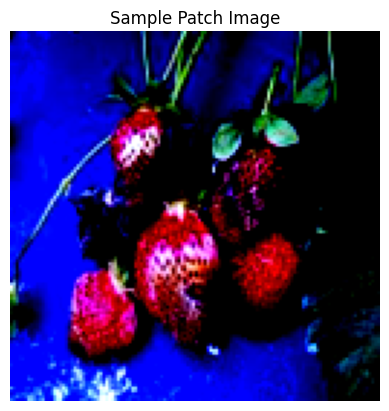

In [227]:
# Get one batch from the patch DataLoader and display the first image
batch_images, _ = next(iter(train_loader))  # images: (B, C, H, W), labels: (B, num_classes)
img = batch_images[0].permute(1, 2, 0).cpu().numpy()
plt.imshow(img)
plt.title("Sample Patch Image")
plt.axis('off')
plt.show()

Detected num_classes from dataset: 6
Train class counts (dataset): [94, 1163, 107, 133, 30, 807]
WeightedRandomSampler detected: skipping class weights (override by passing class_weights).
Epoch 1/100 | train_loss: 0.6618 | val_loss: 0.9913 | train_acc: 0.7751 | val_acc: 0.6502 | lr: 3.00e-04
Saved best checkpoint to best_checkpoint.pth based on val_loss: 0.991314
Epoch 2/100 | train_loss: 0.3084 | val_loss: 0.8788 | train_acc: 0.9010 | val_acc: 0.6855 | lr: 3.00e-04
Saved best checkpoint to best_checkpoint.pth based on val_loss: 0.878825
Epoch 3/100 | train_loss: 0.2401 | val_loss: 0.9820 | train_acc: 0.9237 | val_acc: 0.7102 | lr: 3.00e-04
Epoch 4/100 | train_loss: 0.2237 | val_loss: 1.0232 | train_acc: 0.9323 | val_acc: 0.7244 | lr: 3.00e-04
Epoch 5/100 | train_loss: 0.1374 | val_loss: 0.8876 | train_acc: 0.9529 | val_acc: 0.7279 | lr: 3.00e-04
Epoch 6/100 | train_loss: 0.0897 | val_loss: 0.8672 | train_acc: 0.9722 | val_acc: 0.7562 | lr: 3.00e-04
Saved best checkpoint to best_check

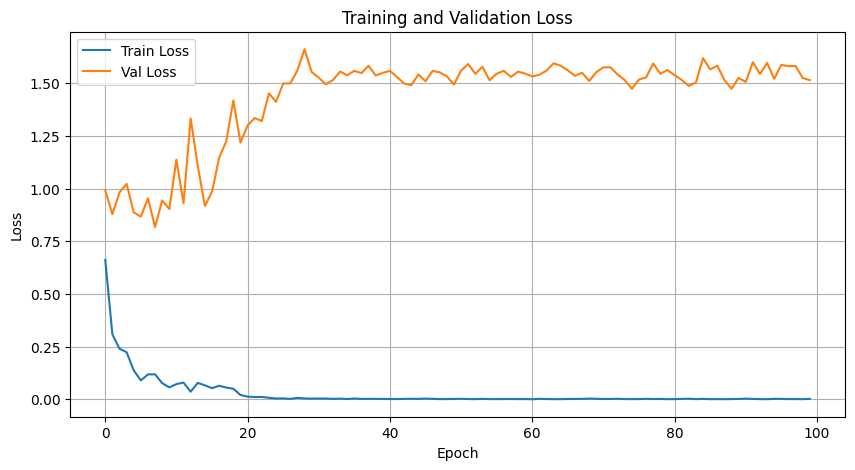

In [230]:
# Example use:
history = train_classifier(model, train_loader, val_loader, num_epochs=100, learning_rate=3e-4, device=DEVICE)

In [239]:
#load best model
checkpoint = torch.load('best_checkpoint.pth')
model.load_state_dict(checkpoint['model_state_dict'])
history = train_classifier(model, train_loader, val_loader, num_epochs=300, learning_rate=0.0001, device=DEVICE)

Detected num_classes from dataset: 6
Train class counts (dataset): [94, 1163, 107, 133, 30, 807]
WeightedRandomSampler detected in train_loader.
DRW enabled. Will apply effective_number weights after 5 warmup epochs.
Backbone frozen for first 3 epochs.
BatchNorm layers set to eval mode (frozen).
Epoch 1/300 | train_loss: 0.8017 | val_loss: 0.9390 | train_acc: 0.6041 | val_acc: 0.8057 | val_bal_acc: 0.5732 | lr: 1.00e-04
Saved best checkpoint to best_checkpoint.pth based on val_loss: 0.938980
Epoch 2/300 | train_loss: 0.8778 | val_loss: 0.8393 | train_acc: 0.5501 | val_acc: 0.8021 | val_bal_acc: 0.5770 | lr: 1.00e-04
Saved best checkpoint to best_checkpoint.pth based on val_loss: 0.839258
Epoch 3/300 | train_loss: 0.6138 | val_loss: 0.7874 | train_acc: 0.6200 | val_acc: 0.7951 | val_bal_acc: 0.5768 | lr: 1.00e-04
Saved best checkpoint to best_checkpoint.pth based on val_loss: 0.787360
Unfroze backbone.
Epoch 4/300 | train_loss: 0.5957 | val_loss: 0.8313 | train_acc: 0.5857 | val_acc: 0.

In [231]:
TEST_PATCH_EXTENDED = '/rds/general/user/pbm24/home/irp_prep/patches_bad_only'
GOOD_PATCH_EXTENDED = "/rds/general/user/pbm24/home/irp_prep/Datasets/antobot_diseases/test_images_gpatches"
image_1 = os.path.join(TEST_PATCH_EXTENDED, "new_017427/patch_0.jpg")
image_2 = os.path.join(TEST_PATCH_EXTENDED, "new_014710/patch_0.jpg")
image_3 = os.path.join(GOOD_PATCH_EXTENDED, "000106/patch_0.jpg") #not part of train or val sets
image_4 = os.path.join(GOOD_PATCH_EXTENDED, "000106/patch_1.jpg") #not part of train or val sets

In [16]:
model.load_state_dict(torch.load('best_checkpoint.pth', map_location=torch.device('cpu'))['model_state_dict'])

<All keys matched successfully>

In [161]:
# Inference function for classification
def predict_class(model, image_path, device=DEVICE):
    image = Image.open(image_path).convert('RGB')
    tf = transform_patch
    x = tf(image).unsqueeze(0).to(DEVICE)
    model = model.to(device)
    model.eval()
    
    with torch.no_grad():
        logits = model(x)  # Use the transformed image tensor
        # Apply softmax to get probabilities
        probs = torch.softmax(logits, dim=1)
        print(probs)
        # Map probabilities to classes
        probs1 = probs.squeeze(0)
        class_names = getattr(train_ds, "class_names", [str(i) for i in range(probs1.shape[0])])
        pred_idx = int(torch.argmax(probs1).item())
        return class_names[pred_idx], probs1[pred_idx].item()


In [64]:
# Example inference
predicted_class, probability = predict_class(model, image_1)
print(f"Predicted Class: {predicted_class}")
print(f"Probability: {probability}")

tensor([[1.8847e-04, 9.9957e-01, 4.7386e-08, 7.8445e-07, 1.6565e-05, 2.8029e-06,
         9.4989e-07, 2.1987e-04]], device='cuda:0')
Predicted Class: Gray Mold
Probability: 0.9995704293251038


In [62]:
predicted_class, probability = predict_class(model, image_3)
print(f"Predicted Class: {predicted_class}")
print(f"Probability: {probability}")

tensor([[1.5064e-04, 1.2594e-04, 2.0928e-06, 6.2350e-06, 5.3829e-04, 7.4930e-05,
         1.3123e-06, 9.9910e-01]], device='cuda:0')
Predicted Class: Healthy-Strawberry
Probability: 0.9991005659103394


Test samples: 132
Test loss: 0.3875
Test accuracy: 0.8939
Class 0 (Anthracnose Fruit Rot): acc=0.8333, support=12
Class 1 (Gray Mold): acc=0.9636, support=55
Class 2 (Powdery Mildew Fruit): acc=0.8095, support=21
Class 3 (Powdery Mildew Leaf): acc=0.9167, support=12
Class 4 (Withered fruit): acc=0.0000, support=3
Class 5 (Healthy-Strawberry): acc=0.9310, support=29


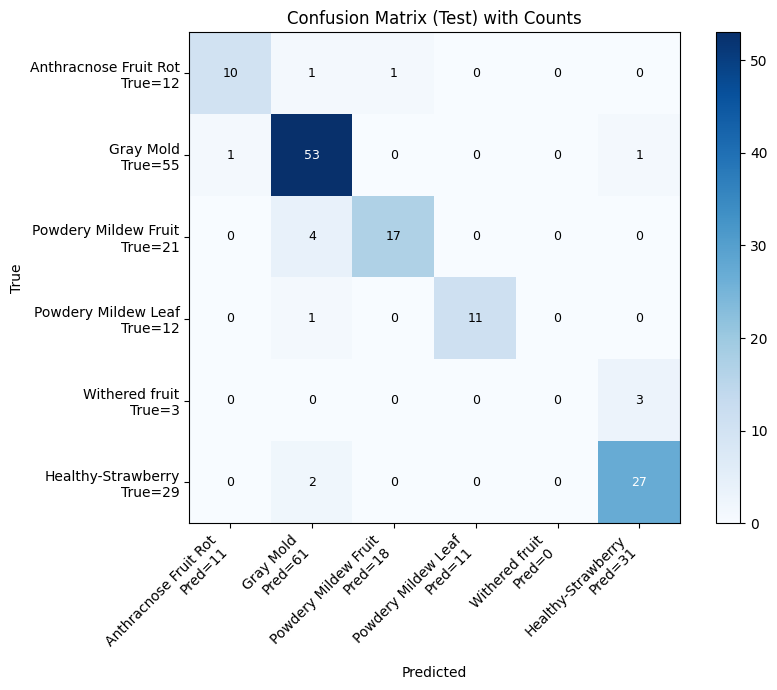

In [18]:
# Evaluate the trained model on a test dataset (expects classes.csv in the test root)
# Use model as already loaded (best checkpoint loaded in previous cells)
model.eval()
criterion = nn.CrossEntropyLoss()

# Metrics containers
total = 0
correct = 0
running_loss = 0.0

# Class metadata
C = num_classes  # from earlier cell
class_names = getattr(test_ds, "class_names", [str(i) for i in range(C)])
class_counts = getattr(test_ds, "class_counts", [0] * C)
conf_mat = torch.zeros(C, C, dtype=torch.long)

with torch.no_grad():
    for images, targets in test_loader:
        images = images.to(DEVICE)
        targets = targets.to(DEVICE)

        logits = model(images)
        loss = criterion(logits, targets)
        running_loss += loss.item() * images.size(0)

        preds = logits.argmax(dim=1)
        correct += (preds == targets).sum().item()
        total += targets.size(0)

        # Update confusion matrix (rows = true, cols = pred)
        for t, p in zip(targets.view(-1), preds.view(-1)):
            conf_mat[t.long(), p.long()] += 1

test_loss = running_loss / max(1, total)
test_acc = correct / max(1, total)
print(f"Test samples: {len(test_ds)}")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

# Per-class accuracy
per_class_acc = (conf_mat.diag().float() / conf_mat.sum(dim=1).clamp(min=1).float()).tolist()
for i, name in enumerate(class_names):
    print(f"Class {i} ({name}): acc={per_class_acc[i]:.4f}, support={int(conf_mat.sum(dim=1)[i].item())}")

# Add predicted/true counts to the confusion matrix plot with cell annotations
pred_counts = conf_mat.sum(dim=0).tolist()
true_counts = conf_mat.sum(dim=1).tolist()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(conf_mat.cpu().numpy(), interpolation="nearest", cmap="Blues")
fig.colorbar(im, ax=ax)

xticks = range(C)
yticks = range(C)
ax.set_xticks(xticks)
ax.set_yticks(yticks)
ax.set_xticklabels([f"{name}\nPred={pred_counts[i]}" for i, name in enumerate(class_names)], rotation=45, ha="right")
ax.set_yticklabels([f"{name}\nTrue={true_counts[i]}" for i, name in enumerate(class_names)])

ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Confusion Matrix (Test) with Counts")

# Annotate each cell with the integer count
cm_np = conf_mat.cpu().numpy()
thresh = cm_np.max() / 2.0 if cm_np.size else 0
for i in range(C):
    for j in range(C):
        val = int(cm_np[i, j])
        ax.text(
            j, i, str(val),
            ha="center", va="center",
            color="white" if val > thresh else "black",
            fontsize=9
        )

fig.tight_layout()
plt.show()